In [3]:
#fonction pour FDMhalo
import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import (NFWPotential, TwoPowerSphericalPotential, AnySphericalPotential,evaluateDensities)
from colossus.cosmology import cosmology
from colossus.halo import concentration, profile_nfw
from scipy.optimize import minimize, fsolve
from math import pi
from galpy.orbit import Orbit       #tri des données euclid
import sys
import pandas as pd
import time
from astropy.constants import G
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, vcirc, FDMDynamicalFrictionForce as FDM_DF
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator
from scipy.signal import argrelextrema

#same but with Core profile

def zeta(z, Omega_m):
    return (18 * np.pi**2 + 82 * (Omega_m - 1) - 39 * (Omega_m - 1)**2) / Omega_m
def r_c(z, M_h, m_22, Omega_m):
    return (1.6 / np.sqrt(1 + z)) * (zeta(z, Omega_m) / zeta(0, Omega_m0))**(-1/6) * (M_h / 1e9)**(-1/3) * m_22**-1
def rho2_z(r_c, m_22, z):
    return 1.9 * (10 * m_22)**-2 * r_c**-4 * 1e9 / ((1 + z)**3)

zgo = 0
cosmo = cosmology.setCosmology('planck18')
Omega_m0 = cosmo.Om(zgo)

def FDMhalo(m22, M):

    Mh=M*0.704
    rc1 = r_c(zgo, M, m22, Omega_m0)
    rhoFDM = rho2_z(rc1, m22, zgo)
    AmpFDM = rhoFDM * 4 * pi * rc1**3

    rc2 = r_c(zgo, M, m22/10, Omega_m0)
    rhoFDM2 = rho2_z(rc2, m22/10, zgo)
    AmpFDM2 = rhoFDM2 * 4 * pi * rc2**3
    
    C2 = concentration.concentration(M*0.704, 'vir', zgo, model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=M*0.704, c=C2, z=zgo, mdef='vir')
    rs = p_nfw.par['rs'] / 0.704
    A=np.log(1+C2)-C2/(1+C2)

    DMhalo2 = NFWPotential(amp=M/A * u.Msun, a=rs*u.kpc)
    r_vals = np.logspace(np.log10(0.001), np.log10(1000), 200)
    FDMhalo_soliton = AnySphericalPotential(dens=lambda r: rhoFDM / ((1 + 0.091 * (r / rc1)**2)**8))

    def cost(params):
        psi, gamma, eta = params
        if psi <= 0 or gamma <= 0 or eta <= 0:
            return np.inf

        def equation(alpha):
            FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
            dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc)
            dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc)
            return (dens_FDM3 - dens_CDM) / dens_CDM

        try:
            alpha_sol = fsolve(equation, 10)[0]
        except:
            return np.inf

        FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha_sol**3) * u.Msun, a=alpha_sol * rc2 * u.kpc, alpha=0, beta=3)
        CoreFDM = TwoPowerSphericalPotential(amp=AmpFDM * (gamma**3) * u.Msun, a=gamma * rc1 * u.kpc, alpha=0, beta=eta)
        total_ref = np.array([evaluateDensities(FDMhalo_soliton, r, 0) + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        total_test = np.array([evaluateDensities(CoreFDM, r * u.kpc, 0 * u.kpc) * 1e9 + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        return np.mean((np.log10(total_ref + 1e-30) - np.log10(total_test + 1e-30))**2)

    result = minimize(cost, x0=[0.5, 12.0, 20.0], bounds=[(0.0001, 0.7 * (1e10 / M) * (10 / m22)), (1, 10), (3, 10)], method='L-BFGS-B')
    psi_opt, gamma_opt, eta_opt = result.x

    def equation(alpha):
        FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
        dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc) * 1e9
        dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc) * 1e9
        return (dens_FDM3 - dens_CDM) / dens_CDM

    alpha_final = fsolve(equation, 10)[0]
    FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha_final**3) * u.Msun, a=alpha_final * rc2 * u.kpc, alpha=0, beta=3)
    CoreFDM = TwoPowerSphericalPotential(amp=(gamma_opt**3) * AmpFDM * u.Msun, a=gamma_opt * rc1 * u.kpc, alpha=0, beta=eta_opt)
    return CoreFDM + FDMhalo3


In [4]:
        #tri des données euclid

def mass_from_mag(MAG_GC):
    return 1.8 * 10**(-0.4 * (MAG_GC + 0.5 - 4.83))

def count_unique(arr):
    return len(set(arr))

Rlimit=0.2 #kpc
MAGlimit = -8

file_path = "ERO_Perseus_GCs_results_for_Pierre_Feb2026.csv"
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
print(df.columns)

#logMs=np.log10(df["logMstar_host"].to_numpy()) #fornax
logMs=df["logMstar_host"].to_numpy()     #perseus
IDgal=df["gal_name"].to_numpy()
MAG_GC=df["GC_VIS_abs"].to_numpy()
RGC=df["GC_dist_kpc"].to_numpy()
print("total number of GCs :",len(RGC))
print('total number of galaxies :',count_unique(IDgal))


sola=np.where(MAG_GC<=MAGlimit)[0]
logMs=logMs[sola]
RGC=RGC[sola]
MAG_GC=MAG_GC[sola]
IDgal=IDgal[sola]

sol=np.where(RGC>Rlimit)[0]
logMs=logMs[sol]
MAG_GC=MAG_GC[sol]
RGC=RGC[sol]
IDgal=IDgal[sol]
MGC=mass_from_mag(MAG_GC)

print("final number of GCs ",len(RGC))
print('final number of galaxies (contening GCs):',count_unique(IDgal))
df_clean = pd.DataFrame({
    "galaxy": IDgal,
    "R": RGC,
    "MAG": MAG_GC,
    "logMs": logMs})

groups = df_clean.groupby("galaxy")
print(df_clean)
for name, g in groups:
    print(f"Galaxie : {name} -> nombre de GC : {len(g)}")

Index(['gal_name', 'ra', 'dec', 'logMstar_host', 'Re_kpc_host', 'GC_dist_kpc',
       'GC_VIS_abs', 'GC_back_prob', 'd_RA_GC_kpc', 'd_DEC_GC_kpc'],
      dtype='str')
total number of GCs : 6827
total number of galaxies : 857
final number of GCs  4487
final number of galaxies (contening GCs): 749
                    galaxy         R       MAG     logMs
0      PERSEUS-DWARF-ID435  4.346720 -8.145142  9.583724
1      PERSEUS-DWARF-ID435  4.516062 -9.624835  9.583724
2      PERSEUS-DWARF-ID435  4.659874 -8.607386  9.583724
3      PERSEUS-DWARF-ID435  2.691397 -8.731130  9.583724
4      PERSEUS-DWARF-ID435  4.262434 -8.238283  9.583724
...                    ...       ...       ...       ...
4482   PERSEUS-DWARF-ID704  0.651502 -8.296533  5.114738
4483  PERSEUS-DWARF-ID1115  1.545330 -8.301363  4.913124
4484  PERSEUS-DWARF-ID1115  1.197845 -9.245631  4.913124
4485  PERSEUS-DWARF-ID1107  0.921620 -8.499107  4.881129
4486  PERSEUS-DWARF-ID1107  0.888654 -8.489498  4.881129

[4487 rows x 4 col

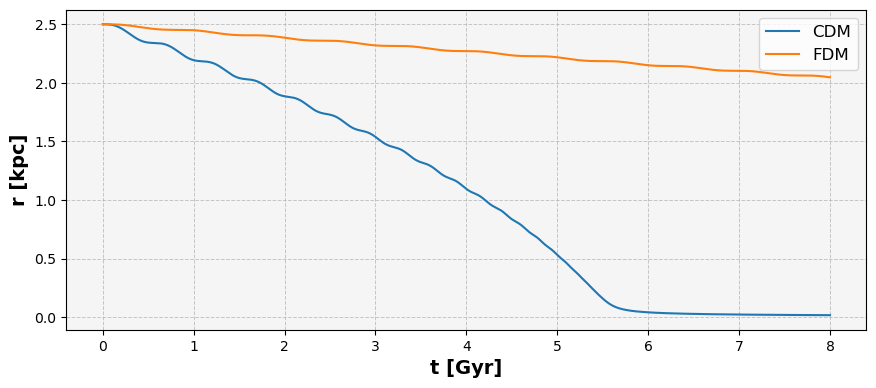

In [79]:
import numpy as np 
import matplotlib.pyplot as plt
import galpy
import pandas as pd
from astropy import units as u
from astropy.constants import G
from galpy.potential import NFWPotential, ChandrasekharDynamicalFrictionForce,TwoPowerTriaxialPotential
from galpy.orbit import Orbit
from scipy.interpolate import PchipInterpolator
from scipy.interpolate import RegularGridInterpolator
from galpy.potential import vcirc
import math


M = 1e9 #Msol
rs = 1.364 #kpc
c = 18.81
Rvir = c * rs 
A_NFW = np.log(1 + c) - c/(1+c)

NFWHalo_sph = NFWPotential(amp=M/A_NFW * u.Msun, a=rs*u.kpc) 
Mobj = 1e6 #Msol
rhm = 1e-2 #kpc
cdf_sph = ChandrasekharDynamicalFrictionForce(GMs=Mobj * u.Msun, rhm=rhm * u.kpc, dens=NFWHalo_sph,minr=0.0001,maxr=1,nr=2001)
R0 = 2.5
vT0 = NFWHalo_sph.vcirc(R0 * u.kpc)
ts = np.linspace(0,8,2000) * u.Gyr
o_cdf_sph = Orbit([R0 * u.kpc, 0.0 * u.km/u.s, vT0 * u.km/u.s, 0.0 * u.kpc, 0.0 * u.km/u.s, 0.0 * u.rad])
o_cdf_sph.integrate(ts, NFWHalo_sph + cdf_sph, method='odeint')

plt.figure(figsize=(10, 4))
plt.plot(ts, o_cdf_sph.r(ts), label='CDM')
plt.xlabel('t [Gyr]', fontsize=14, fontweight='bold')
plt.ylabel('r [kpc]', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.tight_layout(pad=2.5)
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.3)
plt.gca().set_facecolor('whitesmoke')
plt.grid(True, which='both', linestyle='--', linewidth=0.7, alpha=0.7)






FDMHALO=FDMhalo(1,M)
Mobj = 1e6 #Msol
rhm = 1e-2 #kpc
DF=FDM_DF(GMs=Mobj*u.Msun, rhm=rhm*u.kpc,  dens=FDMHALO, m=(1*1e-22)*u.eV,minr=0.0001,maxr=1,nr=2001)
R0 = 2.5
vT0 = FDMHALO.vcirc(R0 * u.kpc)
ts = np.linspace(0,8,2000) * u.Gyr
o_cdf_sph = Orbit([R0 * u.kpc, 0.0 * u.km/u.s, vT0 * u.km/u.s, 0.0 * u.kpc, 0.0 * u.km/u.s, 0.0 * u.rad])
o_cdf_sph.integrate(ts, FDMHALO + DF, method='odeint')


plt.plot(ts, o_cdf_sph.r(ts), label='FDM')
plt.xlabel('t [Gyr]', fontsize=14, fontweight='bold')
plt.ylabel('r [kpc]', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.tight_layout(pad=2.5)
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.3)
plt.gca().set_facecolor('whitesmoke')
plt.grid(True, which='both', linestyle='--', linewidth=0.7, alpha=0.7)
plt.show()


t = ts.value
r = o_cdf_sph.r(ts)

np.savetxt("r(t).txt", np.column_stack((t, r)))

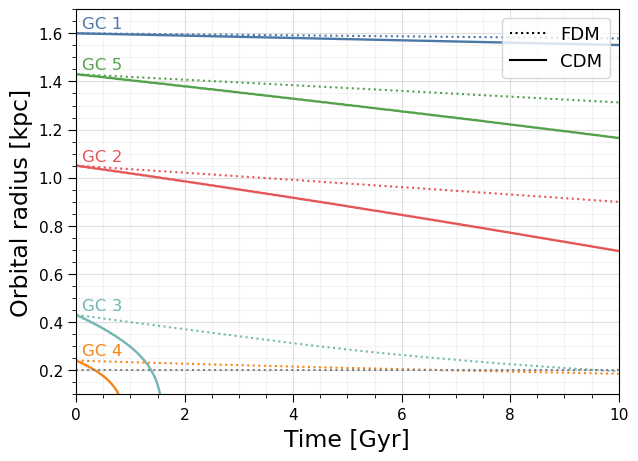

In [18]:
Ms = 2.39e7

halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)


RGC = np.array([1.6, 1.05, 0.43, 0.24, 1.43])#*(2/np.sqrt(3))
MGC = np.array([0.37e5, 1.82e5, 3.63e5, 1.32e5, 1.78e5])
rhm = 0.01
m = 1.54e-22
mfdm=1.54
Mh = M * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)
FDM=FDMhalo(mfdm,M)
ocdm = [[r*u.kpc, 0*u.km/u.s, vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]
ofdm = [[r*u.kpc, 0*u.km/u.s, vcirc(FDM, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]

ts = np.linspace(0, 10, 1001) * u.Gyr
t = np.linspace(0, 10, 1001)


def run(i):
    orb_cdf = Orbit(ocdm[i])
    orb_fdf = Orbit(ofdm[i])
    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    fdf = FDM_DF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV)
    orb_cdf.integrate(ts, NFW_pot+cdf, method='dop853_c')
    orb_fdf.integrate(ts, FDM+fdf, method='dop853_c')
    return orb_cdf.r(ts), orb_fdf.r(ts)

res = Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))
rcdf = np.array([r[0] for r in res])
rfdf = np.array([r[1] for r in res])



fig, ax = plt.subplots(figsize=(7,5))
colors = ['#4C78A8', '#E45756', '#72B7B2', '#F58518', '#54A24B']
#colors=["#D9BE98","#6E9ED6"]#D9BE98   #F0DEC2
for i in range(len(RGC)):
    ax.plot(t, rcdf[i], color=colors[i],linestyle='-', lw=1.7)
    ax.plot(t, rfdf[i], color=colors[i], linestyle=':', lw=1.5)
    ax.text(t[0] + 0.1, rcdf[i][0]+0.02, f"GC {i+1}", fontsize=12,color=colors[i])
ax.plot([], [], color="black", linestyle=":", label=rf"FDM")
ax.plot([], [], color="black", linestyle="-", label=rf"CDM")

ax.axhline(0.2, color='grey', linestyle=':', linewidth=1.5)

ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Orbital radius [kpc]", fontsize=17)

ax.minorticks_on()
"""ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())"""
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_xlim(0, 10)
ax.set_ylim(0.1, 1.7)
ax.legend(frameon=True, fancybox=True, fontsize=13,loc="upper right")
ax.tick_params(axis='both', labelsize=11)
plt.savefig("2.png", dpi=300, bbox_inches="tight")
plt.show()

24627779284.061565


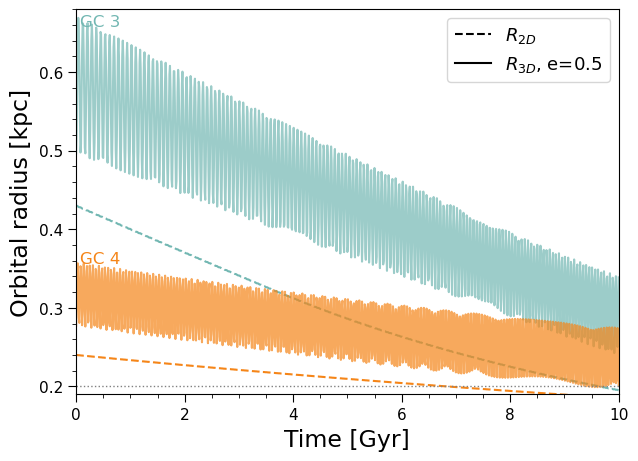

In [21]:
y=[0.162,0.08]
Ms = 2.39e7
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
print(M)
e=0.5
a=np.sqrt(1+e)
p=2/np.sqrt(3)
ts= np.linspace(0.,10,1001)*u.Gyr
GCs=Orbit([[0.43*u.kpc,0.*u.km/u.s,vcirc(FDM,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,vcirc(FDM,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCs3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,vcirc(FDM,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,vcirc(FDM,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s)

GCse=Orbit([[0.43*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCse3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 

fdm_df= [FDM_DF(GMs=3.63e5*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV),
         FDM_DF(GMs=1.32e5*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV),]
         
cdfs=[CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),      ]  
colors = ['#72B7B2', '#F58518']

fig, ax = plt.subplots(figsize=(7,5))
for i, (o1,o2,o3,o4,df) in enumerate(zip(GCs,GCs3,GCse,GCse3,fdm_df)):
    col = colors[i % len(colors)]
    o1.integrate(ts, FDM + df, method='dop853_c')
    o1.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True, label="_nolegend_")
    #o2.integrate(ts, FDM + df, method='dop853_c')
    #o2.plot(color=col, linestyle=':', d1='t', d2='r', overplot=True, label="_nolegend_")
    #plt.plot(ts.value,o2.r(ts), color="purple")
    #o3.integrate(ts, FDM + df, method='dop853_c')
    #o3.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True, label="_nolegend_")
    o4.integrate(ts, FDM + df, method='dop853_c')
    o4.plot(color=col, linestyle='-', d1='t', d2='r',alpha=0.7, overplot=True, label="_nolegend_")
    ax.text(ts[0].value+0.08, o4.R(ts)[0]+y[i], "GC "+str(i+3), color=col,fontsize=12)

ax.plot([], [], color="black", linestyle="--", label=rf"$R_{{2D}}$")
#ax.plot([], [], color="black", linestyle=":", label=rf"$R_{{3D}}$")
#ax.plot([], [], color="black", linestyle="--", label=rf"$R_{{2D}}$, e=0.5")
ax.plot([], [], color="black", linestyle="-", label=rf"$R_{{3D}}$, e=0.5")
ax.axhline(0.2, color='grey',linewidth=1, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Orbital radius [kpc]", fontsize=17)

ax.minorticks_on()


#ax.grid(True, which='major', alpha=0.4)
#ax.grid(True, which='minor', alpha=0.15)

ax.set_xlim(0, 10)
ax.set_ylim(0.19, 0.68)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.tick_params(axis='both', labelsize=11)
ax.legend(frameon=True, fancybox=True, shadow=None, fontsize=13)
plt.savefig("GC34.png", dpi=300, bbox_inches="tight")
plt.show()

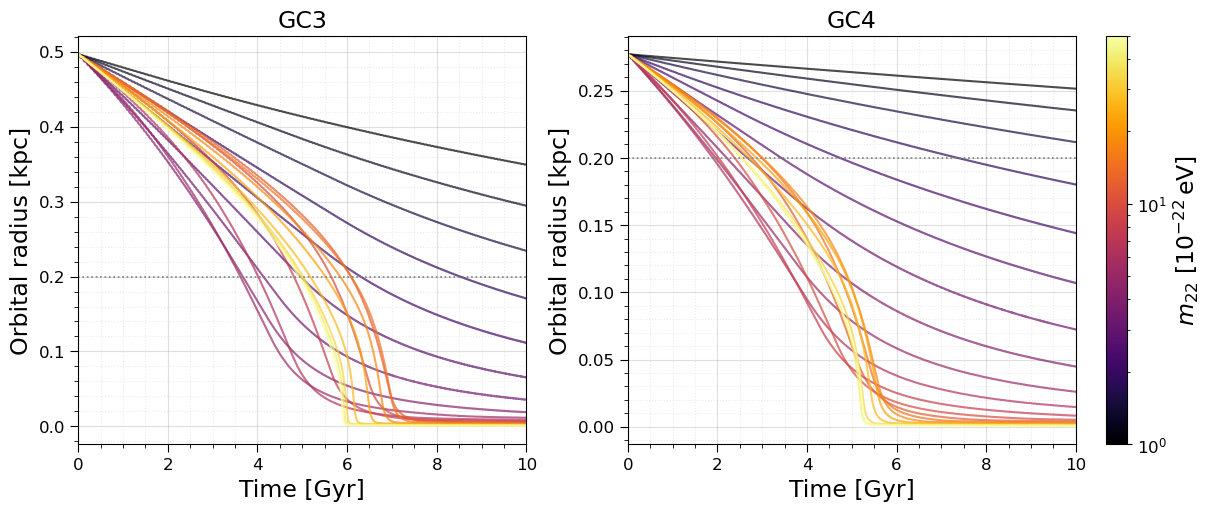

In [23]:
#boucle m22 pour plusieurs GC
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
cosmology.setCosmology('planck15')

Ms = 2.39e7
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)

rhm = 0.01
RGC=np.array([0.43,0.24])*(2/np.sqrt(3))
MGC=np.array([3.63e5,1.32e5])
e=0


ts=np.linspace(0,10,1001)*u.Gyr
t=ts.value
#m22_values = np.linspace(1, 30, 12)
m22_values=np.logspace(np.log10(1),np.log10(50),20)
#m22_values=np.array([0.1,1.64,10,15,20,25,30,35,40,45,50])
all_results=[]

for r,mgc in zip(RGC,MGC):
    gc_results=[]
    for m22 in m22_values:
        fdm=FDMhalo(m22,M)
        orb=Orbit([r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(fdm, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg])
        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=fdm,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,fdm+fdf,method='dop853_c')
        gc_results.append({"m22":m22,"r":orb.r(ts)})
    all_results.append(gc_results)


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, constrained_layout=True)

cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())

for i, ax in enumerate(axes):
    for res in all_results[i]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])),alpha=0.7, lw=1.5)
        
    ax.axhline(0.2, color='grey', linestyle=':', lw=1.2)#, label="0.2 kpc")
    ax.set_title(f'GC{i+3}', fontsize=17)
    ax.set_xlabel("Time [Gyr]", fontsize=17)
    ax.set_ylabel("Orbital radius [kpc]", fontsize=17)
    #ax.legend(loc="upper right")
    ax.set_xlim(0, 10)
    #ax.set_ylim(0,0.45)
    ax.minorticks_on()

    ax.grid(True, which='major', linestyle='-', alpha=0.4)
    ax.grid(True, which='minor', linestyle=':', alpha=0.25)

    ax.tick_params(axis='both', which='major', labelsize=12, length=6)
    ax.tick_params(axis='both', which='minor', length=3)
    #ax.set_ylim(0.18,0.23)

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes, pad=0.02)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=17)
cbar.ax.tick_params(labelsize=12)
plt.savefig("m22_2GC2.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#NFW profile

import time

start = time.time()

ts=np.linspace(0,10,1001)*u.Gyr
rhm=0.01 #kpc
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")

m22_2D = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_2D[name] = np.array([find_m22(i) for i in range(len(R))])


end = time.time()

print(f"Total time: {(end - start)/60:.2f} minutes")
print(f"Total time: {(end - start)/3600:.2f} hours")

"""
m22_3D = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_3D[name] = np.array([find_m22(i) for i in range(len(R))])

m2D=[]
m3D=[]
for name, m22 in m22_2D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R2D
        m2D.append(np.min(m22))

for name, m22 in m22_3D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R3D
        m3D.append(np.min(m22))







#calcul pour r2D et 3D avec excentricité
e=0.5

m22_e2D = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit
        

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit
        

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_e2D[name] = np.array([find_m22(i) for i in range(len(R))])


m22_e3D = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit
        

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_e3D[name] = np.array([find_m22(i) for i in range(len(R))])

me2D=[]
me3D=[]
for name, m22 in m22_e2D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        me2D.append(np.min(m22))

for name, m22 in m22_e3D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        me3D.append(np.min(m22))
"""

In [13]:
#nouveau profil
ts=np.linspace(0,10,1001)*u.Gyr
rhm=0.01 #kpc
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")


m22_c2D = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    
    def test_local(i, m22):
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_c2D[name] = np.array([find_m22(i) for i in range(len(R))])



"""
m22_c3D = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_c3D[name] = np.array([find_m22(i) for i in range(len(R))])

mc2D=[]
mc3D=[]
for name, m22 in m22_c2D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R2D
        mc2D.append(np.min(m22))

for name, m22 in m22_c3D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R3D
        mc3D.append(np.min(m22))







#calcul pour r2D et 3D avec excentricité
e=0.5

m22_ce2D = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, pot + fdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_ce2D[name] = np.array([find_m22(i) for i in range(len(R))])


m22_ce3D = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, pot + fdf, method='dop853_c')
        ap = argrelextrema(orb.r(ts), np.greater)[0]
        return np.min(orb.r(ts)[ap])<Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_ce3D[name] = np.array([find_m22(i) for i in range(len(R))])

mce2D=[]
mce3D=[]
for name, m22 in m22_ce2D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        mce2D.append(np.min(m22))

for name, m22 in m22_ce3D.items():
    if len(m22) > 0:
        #print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        mce3D.append(np.min(m22))
"""

FORNAX-DWARF-10 | GC 0 | m22 = 99.99694854736327
FORNAX-DWARF-13 | GC 0 | m22 = 1.2946615600585938
FORNAX-DWARF-20 | GC 0 | m22 = 1.9781869506835936
FORNAX-DWARF-28 | GC 0 | m22 = 1.654732971191406
FORNAX-DWARF-4 | GC 0 | m22 = 99.99694854736327
FORNAX-DWARF-6 | GC 0 | m22 = 1.9659811401367187
FORNAX-DWARF-6 | GC 1 | m22 = 29.014057312011715
FORNAX-DWARF-8 | GC 0 | m22 = 16.92420196533203
FORNAX-DWARF-8 | GC 1 | m22 = 99.99694854736327


'\nm22_c3D = {}\nfor name, g in groups:\n    R = g["R"].to_numpy()*2/np.sqrt(3)\n    N_amas=len(R)\n    MAG = g["MAG"].to_numpy()\n    logM = g["logMs"].iloc[0]\n    M = mass_from_mag(MAG)\n    Mg = 10**model.mean_log_halo_mass(logM)\n    Mh = Mg * 0.704\n    c = concentration.concentration(Mh,\'vir\',0,model=\'prada12\')\n    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef=\'vir\')\n    rs = p_nfw.par[\'rs\']/0.704\n    A = np.log(1+c)-c/(1+c)\n    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)\n\n    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]\n\n    def cdm_local(i):\n        orb = Orbit(os[i])\n        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)\n        orb.integrate(ts, NFW_pot+cdf, method=\'dop853_c\')\n        return np.min(orb.r(ts)) < Rlimit\n\n    valid = np.where([cdm_local(i) for i in range(len(R))])[0]\n    R = R[valid]\n    M = M[valid]\n    os = [os[i] for i in valid]\n    #print(f"Galaxie : {nam

In [ ]:
#np.savez("m22_Core_Fornax2.npz",mc2D=mc2D,mc3D=mc3D,mce2D=mce2D,mce3D=mce3D)
#np.savez("m22_NFW_Fornax2.npz",m2D=m2D,m3D=m3D,me2D=me2D,me3D=me3D)

In [ ]:
print(mce3D)

In [ ]:
# plot 1 galaxy 4 trajectoires
ts = np.linspace(0, 10, 1001) * u.Gyr

rhm = 0.01  # kpc
halocat = FakeSim()
model = PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df = pd.DataFrame({"ID": IDgal, "R": RGC, "MAG": MAG_GC, "logMs": logMs})
target = "PERSEUS-DWARF-ID10"
sel = np.where(IDgal == target)[0]
Rproj = RGC[sel]
Rdeproj = Rproj * 2 / np.sqrt(3)        #R2D ou R3D
e=0.5                                   #excentricité
MGC_fornax = MGC[sel]
g = df.groupby("ID").get_group(target)
logM = g["logMs"].iloc[0]
Mg = 10**model.mean_log_halo_mass(logM)
mgc = MGC_fornax[0]
colors = ["#4C9ED9", "#F0C75E", "#5CB85C", "#C44E52"]#5CB85C

m22_list = [3.07,2.17,2.25,1.98]

configs = [
    {"R": Rdeproj[0], "fac": np.sqrt(1 + e), "label": r"$R_{3D}, e=0.5$", "m22": m22_list[0]},
    {"R": Rproj[0],   "fac": np.sqrt(1 + e), "label": r"$R_{2D}, e=0.5$", "m22": m22_list[1]},
    {"R": Rdeproj[0], "fac": 1.0,           "label": r"$R_{3D}, e=0$",   "m22": m22_list[2]},
    {"R": Rproj[0],   "fac": 1.0,           "label": r"$R_{2D}, e=0$",   "m22": m22_list[3]},]

results = []

for cfg in configs:
    m = cfg["m22"] 
    pot=FDMhalo(m,Mg)
    o = [cfg["R"]*u.kpc,  0 * u.km / u.s, cfg["fac"] * vcirc(pot, cfg["R"]*u.kpc)*u.km / u.s,0*u.kpc, 0 * u.km / u.s,0 * u.deg ]
    orb = Orbit(o)
    DF = FDM_DF(GMs=mgc * u.Msun, rhm=rhm * u.kpc, dens=pot, m=(cfg["m22"]*1e-22)*u.eV )
    orb.integrate(ts, pot + DF, method='dop853_c')
    results.append({"label": cfg["label"] + rf", $m_{{22}}={cfg['m22']}$","r": orb.r(ts)})

# plot
t = ts.value
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for i, res in enumerate(results):
    ax.plot(t,res["r"],lw=1.5,color=colors[i % len(colors)],label=res["label"])
ax.axhline(0.2, color='black', linestyle='--', lw=1)#, label='0.2 kpc')
ax.set_title('FORNAX-DWARF-10', fontsize=16)
ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$', fontsize=14)
ax.set_ylabel(r'$r\ \mathrm{[kpc]}$', fontsize=14)
ax.set_xlim(0, 10)
ax.set_xticks(np.arange(0, 10.5, 1.0))              
ax.set_xticks(np.arange(0, 10.5, 0.5), minor=True) 
ax.minorticks_on()

ax.grid(True, which='major', linestyle='-', alpha=0.35, linewidth=0.8)
ax.grid(True, which='minor', linestyle=':', alpha=0.25, linewidth=0.6)

ax.tick_params(axis='both', which='major', labelsize=12, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=False,fontsize=(12))
plt.show()

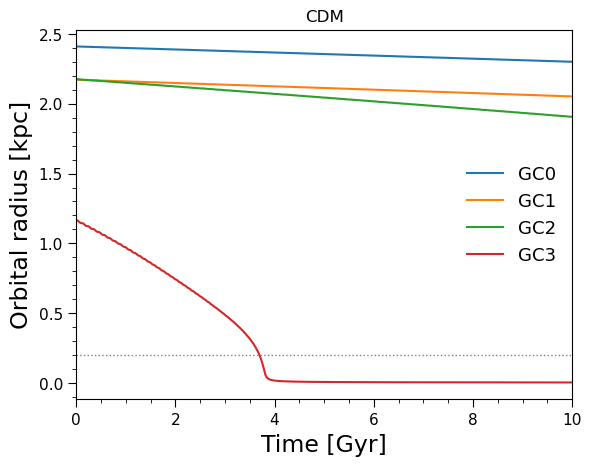

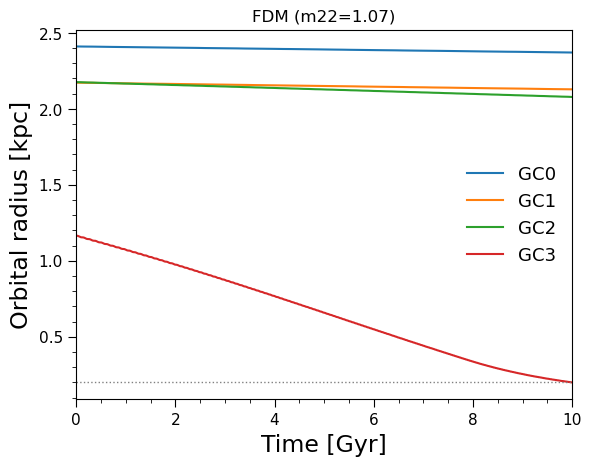

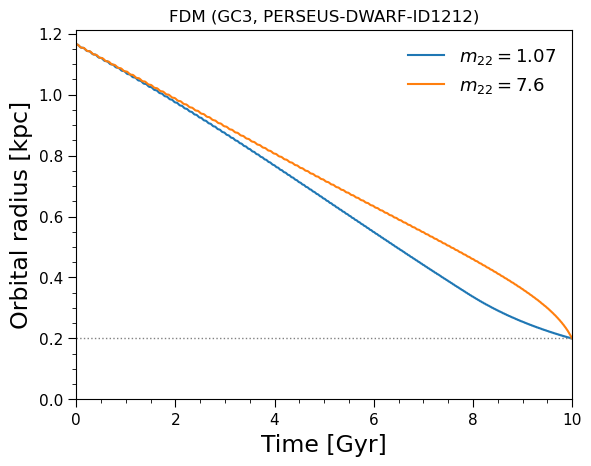

In [65]:
#plot for galaxies that have changed m22          PERSEUS-DWARF-ID1018   and  PERSEUS-DWARF-ID1212

ts=np.linspace(0,10,1001)*u.Gyr   
t=ts.value
rhm=0.01
e=0
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")

fig,ax=plt.subplots()
color=["blue","orange"]
targets=["PERSEUS-DWARF-ID1212"]
for (i, name) in enumerate(targets):
    g=groups.get_group(name)
    R=g["R"].to_numpy()
    MAG=g["MAG"].to_numpy()
    M=mass_from_mag(MAG)
    logM=g["logMs"].iloc[0]
    Mg=10**model.mean_log_halo_mass(logM)
    Mh=Mg*0.704
    c=concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw=profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs=p_nfw.par['rs']/0.704
    A=np.log(1+c)-c/(1+c)
    NFW_pot=NFWPotential(amp=Mg/A*u.Msun,a=rs*u.kpc)
    for GC in range(len(R)):
        orb=Orbit([R[GC]*u.kpc,0*u.km/u.s,vcirc(NFW_pot,R[GC]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        cdf=CDFF(GMs=M[GC]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot)
        orb.integrate(ts,NFW_pot+cdf,method='dop853_c')
        ax.plot(t,orb.r(ts),label=rf"GC{GC}")
ax.axhline(0.2,color='grey',linestyle=':',lw=1)
ax.set_xlabel("Time [Gyr]",fontsize=17)
ax.set_ylabel("Orbital radius [kpc]",fontsize=17)
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_title("CDM")
ax.legend(frameon=False,fontsize=13)
plt.xlim(0,10)
plt.show()



fig,ax=plt.subplots()
color=["blue","orange"]
m22=[1.07]
for (i, name), m in zip(enumerate(targets), m22):
    g=groups.get_group(name)
    R=g["R"].to_numpy()
    MAG=g["MAG"].to_numpy()
    M=mass_from_mag(MAG)
    logM=g["logMs"].iloc[0]
    Mg=10**model.mean_log_halo_mass(logM)
    for GC in range(len(R)):
        pot=FDMhalo(m,Mg)
        orb=Orbit([R[GC]*u.kpc,0*u.km/u.s,vcirc(pot,R[GC]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf=FDM_DF(GMs=M[GC]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m*1e-22)*u.eV)
        orb.integrate(ts,pot+fdf,method='dop853_c')
        ax.plot(t,orb.r(ts),label=rf"GC{GC}")
        
ax.axhline(0.2,color='grey',linestyle=':',lw=1)
ax.set_xlabel("Time [Gyr]",fontsize=17)
ax.set_ylabel("Orbital radius [kpc]",fontsize=17)
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_title(rf"FDM (m22={m22[0]})")
ax.legend(frameon=False,fontsize=13)
plt.xlim(0,10)
plt.show()




fig,ax=plt.subplots()
color=plt.cm.viridis(np.linspace(0,1,len(m22)))
m22=[1.07,7.6]   #1212
#m22=[48.6,100]

for i,name in enumerate(targets):
    g=groups.get_group(name)
    R=g["R"].to_numpy()
    MAG=g["MAG"].to_numpy()
    M=mass_from_mag(MAG)
    logM=g["logMs"].iloc[0]
    Mg=10**model.mean_log_halo_mass(logM)
    GC=3                                                                #GC0 pour 1018         GC3 pour 1212
    for j,m in enumerate(m22):
        pot=FDMhalo(m,Mg)
        orb=Orbit([R[GC]*u.kpc,0*u.km/u.s,vcirc(pot,R[GC]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf=FDM_DF(GMs=M[GC]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m*1e-22)*u.eV)
        orb.integrate(ts,pot+fdf,method='dop853_c')
        ax.plot(t,orb.r(ts),label=rf"$m_{{22}}={m}$")

ax.axhline(0.2,color='grey',linestyle=':',lw=1)
ax.set_xlabel("Time [Gyr]",fontsize=17)
ax.set_ylabel("Orbital radius [kpc]",fontsize=17)
ax.minorticks_on()
ax.tick_params(axis='both',which='major',labelsize=11,length=6)
ax.tick_params(axis='both',which='minor',length=3)
ax.set_title(rf"FDM (GC{GC}, {targets[0]})")
ax.legend(frameon=False,fontsize=13)
plt.xlim(0,10)
plt.ylim(0)
plt.show()

In [ ]:
ts=np.linspace(0,10,1001)*u.Gyr      #963 : 2.6495
rhm=0.01
targets=["PERSEUS-DWARF-ID100","PERSEUS-DWARF-ID136","PERSEUS-DWARF-ID1241"]
results={t:[] for t in targets}
m22_ce3D={}
e=0
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")

for name in targets:
    g=groups.get_group(name)
    R=g["R"].to_numpy() #*2/np.sqrt(3)
    MAG=g["MAG"].to_numpy()
    M=mass_from_mag(MAG)
    logM=g["logMs"].iloc[0]
    Mg=10**model.mean_log_halo_mass(logM)
    Mh=Mg*0.704
    c=concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw=profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs=p_nfw.par['rs']/0.704
    A=np.log(1+c)-c/(1+c)
    NFW_pot=NFWPotential(amp=Mg/A*u.Msun,a=rs*u.kpc)
    os=[[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in R]
    
    def cdm_local(i):
        orb=Orbit(os[i])
        cdf=CDFF(GMs=M[i]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot)
        orb.integrate(ts,NFW_pot+cdf,method='dop853_c')
        #ap=argrelextrema(orb.r(ts),np.greater)[0]
        return np.min(orb.r(ts))<Rlimit          #eturn np.min(orb.r(ts)[ap])<Rlimit
    valid=np.where([cdm_local(i) for i in range(len(R))])[0]
    R=R[valid]
    M=M[valid]
    os=[os[i] for i in valid]
    
    def test_local(i,m22):
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        fdf=FDM_DF(GMs=M[i]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,pot+fdf,method='dop853_c')
        #ap=argrelextrema(orb.r(ts),np.greater)[0]
        return np.min(orb.r(ts))<Rlimit
        
    def find_m22(i,lo=0.01,hi=100.0,eps=0.01):
        while hi-lo>eps:
            mid=0.5*(hi+lo)
            if test_local(i,mid):hi=mid
            else:lo=mid
        return 0.5*(hi+lo)
    m22_ce3D[name]=np.array([find_m22(i) for i in range(len(R))])
    results[name]=[]
    m22_list=m22_ce3D[name]
    
    for i in range(len(R)):
        m22=min(m22_list)
        pot=FDMhalo(m22,Mg)
        orb=Orbit([R[i]*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(pot,R[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg])
        DF=FDM_DF(GMs=M[i]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,pot+DF,method='dop853_c')
        results[name].append({"label":f"GC {i+1}","r":orb.r(ts)})



t=ts.value

In [1]:
#3 galaxies
print(R)
fig,ax=plt.subplots(figsize=(7,5))
colors=["#8fb996","#f08060","#f1d36b"]
lab=["GC ID100","GC ID136","GC ID1241"]
idx=[0,1,0]
alp=[0.6,0.9,0.9]
for i,name in enumerate(targets):
    m22=min(m22_ce3D[name])
    r=results[name][idx[i]]["r"]
    ax.plot(t,r,color=colors[i],alpha=alp[i],lw=2,label=rf"{lab[i]} $m_{{22}}={m22:.2f}$")
ax.axhline(0.2,color='grey',linestyle=':',lw=1)
ax.set_xlabel("Time [Gyr]",fontsize=17)
ax.set_ylabel("Orbital radius [kpc]",fontsize=17)
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
plt.ylim(0.13,0.8)
plt.xlim(0,10)
ax.legend(frameon=False,fontsize=13)
plt.savefig("3galaxies.png", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'R' is not defined

In [ ]:
# decompte
ts=np.linspace(0,10,1001)*u.Gyr
rhm=0.01 #kpc
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")

total_valid = 0

for name, g in groups:
    R = g["R"].to_numpy()
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)

    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]

    total_valid += len(valid)

print(f"Nombre total de GC timing problem : {total_valid}")